# Step 4 — Ethereum: stazionarietà e cambiamenti strutturali

Cerchiamo radici unitarie, sensibilità alla specificazione e cambiamenti delle medie giornaliere.
Le conclusioni riguardano questo campione; un rifiuto statistico non identifica una causa economica.

**Risultati eseguiti.** In 19 confronti locali su 36 ADF e KPSS rifiutano entrambe le ipotesi: le fee richiedono approfondimenti, non una differenziazione automatica. Cinque segnali esplorativi di cambiamento delle medie giornaliere si concentrano fra l’8 e il 17 aprile 2026; le cause non sono verificate. Dettagli e limiti in [findings.md](findings.md).

Fonte: artefatti verificati dello [step 1](../step1/dataset_ethereum.ipynb), dataset
`e7b17cfb-320d-4e6c-93c1-06dbc24f312d`, [checklist, punto 4](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).
Fee in gwei/gas per i livelli, logaritmi di `1 + fee in wei/gas` per le trasformazioni.
Nessuna riga originale viene eliminata o corretta. I valori mancanti ai bordi sono esclusi solo dal test che li richiede.

**Metodo e limiti.** ADF: H₀ radice unitaria; KPSS: H₀ stazionarietà; PP è un controllo complementare.
I test locali usano tre finestre contigue di 8192 blocchi, senza saltare osservazioni;
i cambiamenti di media usano tutte le giornate complete. I p-value dei test locali sono esplorativi,
non corretti per confronti multipli: contano coerenza fra test, finestre e specificazioni, non un singolo rifiuto.

Riferimenti dei metodi: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html),
[KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html),
[PP](https://arch.readthedocs.io/en/latest/unitroot/generated/arch.unitroot.PhillipsPerron.html),
[CUSUM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.breaks_cusumolsresid.html).

## 1. Ambiente e dati verificati

Ricarichiamo gli artefatti dello step 1 in un kernel nuovo e controlliamo identità, numerosità e continuità.
Salviamo i risultati esclusivamente nella cartella diagnostica di questo step.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from arch.unitroot import PhillipsPerron
from IPython.display import display
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file()
)
input_directory = project_root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((input_directory / "preprocessing_summary.json").read_text())
df = pd.read_parquet(input_directory / "ethereum_blocks_diagnostics.parquet")
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
assert len(df) == summary["rows"]
assert np.all(np.diff(df["block_number"]) == 1)
output_directory = project_root / "outputs/notebook_diagnostics/ethereum/step4"
output_directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 10)
print("Blocchi:", len(df), "| SHA-256 fonte:", summary["dataset_sha256"])

Blocchi: 1654536 | SHA-256 fonte: 4a8482552e3730ad68243a042eaa92b112450b36411f11a18947e9682d2e62e0


## 2. Finestre contigue e variabili

Dichiariamo posizione, date e trasformazioni prima dei test, così i lag restano distanze fra blocchi consecutivi.
Le finestre iniziale, centrale e finale rendono visibile la sensibilità al periodo senza pretendere copertura completa.

In [2]:
WINDOW = 8192
ALPHA = 0.05
starts = {"inizio": 0, "centro": (len(df) - WINDOW) // 2, "fine": len(df) - WINDOW}
windows = {name: df.iloc[start : start + WINDOW] for name, start in starts.items()}
window_report = pd.DataFrame(
    [
        {
            "finestra": name,
            "righe": len(part),
            "primo_blocco": int(part.block_number.iloc[0]),
            "ultimo_blocco": int(part.block_number.iloc[-1]),
            "inizio_UTC": pd.to_datetime(part.timestamp.iloc[0], unit="s", utc=True),
            "fine_UTC": pd.to_datetime(part.timestamp.iloc[-1], unit="s", utc=True),
        }
        for name, part in windows.items()
    ]
)
window_report.to_csv(output_directory / "test_windows.csv", index=False)
display(window_report)
levels = ["base_fee_gwei", "X", "priority_fee_p50_gwei", "priority_fee_p90_gwei"]
transformed = [
    "log_base_fee_per_gas",
    "log_effective_priority_fee_per_gas_p50",
    "log_effective_priority_fee_per_gas_p90",
    "priority_fee_dispersion",
]
differences = ["base_log_fee_return", "delta_X", "delta_log_p50", "delta_log_p90"]
stationarity_rows = []


def stationarity_tests(columns, family):
    rows = []
    for name, part in windows.items():
        for column in columns:
            values = part[column].dropna().to_numpy()
            assert len(values) >= WINDOW - 1 and np.isfinite(values).all()
            # Lag fissato: confronto omogeneo fra serie, senza selezione nascosta.
            adf = adfuller(values, maxlag=10, regression="c", autolag=None)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result = kpss(values, regression="c", nlags=10)
            rows.append(
                {
                    "famiglia": family,
                    "finestra": name,
                    "variabile": column,
                    "n": len(values),
                    "adf_stat": adf[0],
                    "adf_p": adf[1],
                    "kpss_stat": result[0],
                    "kpss_p": result[1],
                    "kpss_p_limitato": any(
                        issubclass(w.category, InterpolationWarning) for w in caught
                    ),
                    "lag": 10,
                }
            )
    stationarity_rows.extend(rows)
    return pd.DataFrame(rows)

,finestra,righe,primo_blocco,ultimo_blocco,inizio_UTC,fine_UTC
0,inizio,8192,23935694,23943885,2025-12-03 21:49:23+00:00,2025-12-05 02:46:23+00:00
1,centro,8192,24758866,24767057,2026-03-28 21:49:11+00:00,2026-03-30 01:13:11+00:00
2,fine,8192,25582038,25590229,2026-07-21 15:36:47+00:00,2026-07-22 19:02:47+00:00


## 3. ADF e KPSS sui livelli

Verifichiamo se livelli delle fee e utilizzo sono compatibili con una media stabile nelle singole finestre.
Le due ipotesi nulle opposte aiutano a distinguere evidenza concorde da risultati ambigui.

In [3]:
level_tests = stationarity_tests(levels, "livelli")
display(level_tests.round(5))

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", auto

,famiglia,finestra,variabile,n,adf_stat,adf_p,kpss_stat,kpss_p,kpss_p_limitato,lag
0,livelli,inizio,base_fee_gwei,8192,-4.37514,0.00033,15.63440,0.01000,True,10
1,livelli,inizio,X,8192,-31.15506,0.00000,0.01826,0.10000,True,10
2,livelli,inizio,priority_fee_p50_gwei,8192,-27.09964,0.00000,0.07711,0.10000,True,10
3,livelli,inizio,priority_fee_p90_gwei,8192,-25.86263,0.00000,0.28726,0.10000,True,10
4,livelli,centro,base_fee_gwei,8192,-8.27291,0.00000,8.88295,0.01000,True,10
5,livelli,centro,X,8192,-34.96866,0.00000,0.00265,0.10000,True,10
6,livelli,centro,priority_fee_p50_gwei,8192,-25.57569,0.00000,0.56980,0.02595,False,10
7,livelli,centro,priority_fee_p90_gwei,8192,-24.61077,0.00000,2.01356,0.01000,True,10
8,livelli,fine,base_fee_gwei,8192,-6.84928,0.00000,11.28544,0.01000,True,10
9,livelli,fine,X,8192,-24.99662,0.00000,0.01584,0.10000,True,10


## 4. ADF e KPSS sulle trasformazioni

Ripetiamo i controlli sui log delle fee e sulla dispersione p90–p50, senza cambiare i campioni.
Confrontiamo queste rappresentazioni con i livelli, mantenendo lo zero convenzionale dei blocchi vuoti.

In [4]:
transformed_tests = stationarity_tests(transformed, "trasformazioni")
display(transformed_tests.round(5))

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", auto

,famiglia,finestra,variabile,n,adf_stat,adf_p,kpss_stat,kpss_p,kpss_p_limitato,lag
0,trasformazioni,inizio,log_base_fee_per_gas,8192,-4.57514,0.00014,19.35177,0.01,True,10
1,trasformazioni,inizio,log_effective_priority_fee_per_gas_p50,8192,-18.18529,0.00000,3.68640,0.01,True,10
2,trasformazioni,inizio,log_effective_priority_fee_per_gas_p90,8192,-18.97825,0.00000,8.58750,0.01,True,10
3,trasformazioni,inizio,priority_fee_dispersion,8192,-18.72327,0.00000,3.80353,0.01,True,10
4,trasformazioni,centro,log_base_fee_per_gas,8192,-9.47962,0.00000,9.76672,0.01,True,10
5,trasformazioni,centro,log_effective_priority_fee_per_gas_p50,8192,-19.42768,0.00000,11.71448,0.01,True,10
6,trasformazioni,centro,log_effective_priority_fee_per_gas_p90,8192,-19.01894,0.00000,21.59118,0.01,True,10
7,trasformazioni,centro,priority_fee_dispersion,8192,-20.16775,0.00000,6.18595,0.01,True,10
8,trasformazioni,fine,log_base_fee_per_gas,8192,-6.35408,0.00000,13.07607,0.01,True,10
9,trasformazioni,fine,log_effective_priority_fee_per_gas_p50,8192,-11.46077,0.00000,13.62681,0.01,True,10


## 5. Prime differenze e variazione della base fee

Studiamo variazioni fra blocchi e log return della base fee per vedere se attenuano la persistenza dei livelli.
Il return guarda al blocco successivo: qui è un oggetto descrittivo, non una variabile disponibile alla decisione.

In [5]:
difference_tests = stationarity_tests(differences, "differenze")
display(difference_tests.round(5))

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/774535834.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=10, regression="c", auto

,famiglia,finestra,variabile,n,adf_stat,adf_p,kpss_stat,kpss_p,kpss_p_limitato,lag
0,differenze,inizio,base_log_fee_return,8192,-31.28450,0.0,0.01555,0.1,True,10
1,differenze,inizio,delta_X,8191,-50.81681,0.0,0.00077,0.1,True,10
2,differenze,inizio,delta_log_p50,8191,-45.82165,0.0,0.00089,0.1,True,10
3,differenze,inizio,delta_log_p90,8191,-47.59014,0.0,0.00097,0.1,True,10
4,differenze,centro,base_log_fee_return,8192,-35.07422,0.0,0.00208,0.1,True,10
5,differenze,centro,delta_X,8192,-52.53802,0.0,0.00140,0.1,True,10
6,differenze,centro,delta_log_p50,8192,-47.54912,0.0,0.00109,0.1,True,10
7,differenze,centro,delta_log_p90,8192,-47.90641,0.0,0.00103,0.1,True,10
8,differenze,fine,base_log_fee_return,8191,-25.07028,0.0,0.01549,0.1,True,10
9,differenze,fine,delta_X,8192,-42.57676,0.0,0.00133,0.1,True,10


## 6. Sensibilità a trend e lag

Sulla finestra centrale confrontiamo intercetta e trend deterministico con 1, 10 e 30 lag.
Cerchiamo conclusioni che cambiano specificazione; i p-value restano diagnostiche esplorative.

In [6]:
sensitivity_rows = []
for column in ["X", *transformed]:
    values = windows["centro"][column].dropna().to_numpy()
    for trend in ["c", "ct"]:
        for lag in [1, 10, 30]:
            adf = adfuller(values, maxlag=lag, regression=trend, autolag=None)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result = kpss(values, regression=trend, nlags=lag)
            sensitivity_rows.append(
                {
                    "variabile": column,
                    "trend": trend,
                    "lag": lag,
                    "adf_p": adf[1],
                    "kpss_p": result[1],
                    "kpss_p_limitato": any(
                        issubclass(w.category, InterpolationWarning) for w in caught
                    ),
                }
            )
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(output_directory / "lag_trend_sensitivity.csv", index=False)
for trend, part in sensitivity.groupby("trend"):
    print("Specificazione:", trend)
    display(part.pivot(index="variabile", columns="lag", values=["adf_p", "kpss_p"]).round(5))

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/1751512291.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=lag, regression=trend, autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/1751512291.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=lag, regression=trend

Specificazione: c


/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/1751512291.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=lag, regression=trend, autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/1751512291.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=lag, regression=trend

adf_p           kpss_p            
lag                                       1    10   30     1     10    30
variabile                                                                
X                                        0.0  0.0  0.0   0.10  0.10  0.10
log_base_fee_per_gas                     0.0  0.0  0.0   0.01  0.01  0.01
log_effective_priority_fee_per_gas_p50   0.0  0.0  0.0   0.01  0.01  0.01
log_effective_priority_fee_per_gas_p90   0.0  0.0  0.0   0.01  0.01  0.01
priority_fee_dispersion                  0.0  0.0  0.0   0.01  0.01  0.01

Specificazione: ct


adf_p           kpss_p            
lag                                       1    10   30     1     10    30
variabile                                                                
X                                        0.0  0.0  0.0   0.10  0.10  0.10
log_base_fee_per_gas                     0.0  0.0  0.0   0.01  0.01  0.01
log_effective_priority_fee_per_gas_p50   0.0  0.0  0.0   0.01  0.01  0.01
log_effective_priority_fee_per_gas_p90   0.0  0.0  0.0   0.01  0.01  0.01
priority_fee_dispersion                  0.0  0.0  0.0   0.01  0.01  0.01

## 7. Phillips–Perron come controllo aggiuntivo

PP corregge la dipendenza di breve periodo con una stima della varianza di lungo periodo, invece dei lag ADF.
Lo confrontiamo su utilizzo e trasformazioni; non è una prova indipendente ottenuta da nuovi dati.

In [7]:
pp_rows = []
for name, part in windows.items():
    for column in ["X", *transformed]:
        result = PhillipsPerron(part[column].dropna().to_numpy(), lags=10, trend="c")
        pp_rows.append(
            {
                "finestra": name,
                "variabile": column,
                "stat": result.stat,
                "p": result.pvalue,
                "lag_varianza": result.lags,
            }
        )
pp_tests = pd.DataFrame(pp_rows)
pp_tests.to_csv(output_directory / "phillips_perron.csv", index=False)
display(pp_tests.round(5))

,finestra,variabile,stat,p,lag_varianza
0,inizio,X,-111.90636,0.0,10
1,inizio,log_base_fee_per_gas,-5.51466,0.0,10
2,inizio,log_effective_priority_fee_per_gas_p50,-82.54832,0.0,10
3,inizio,log_effective_priority_fee_per_gas_p90,-90.58915,0.0,10
4,inizio,priority_fee_dispersion,-81.50964,0.0,10
5,centro,X,-126.39810,0.0,10
6,centro,log_base_fee_per_gas,-16.17877,0.0,10
7,centro,log_effective_priority_fee_per_gas_p50,-88.79081,0.0,10
8,centro,log_effective_priority_fee_per_gas_p90,-93.25907,0.0,10
9,centro,priority_fee_dispersion,-86.63331,0.0,10


## 8. Interpretazione congiunta e trasformazioni

Classifichiamo i risultati ADF/KPSS secondo la tabella della checklist e segnaliamo dipendenza dalla specificazione.
Non differenziamo automaticamente l’utilizzo limitato in [0, 2], né sostituiamo la ricorrenza della base fee con un modello libero.

In [8]:
def joint_interpretation(adf_p, kpss_p):
    if adf_p < ALPHA and kpss_p >= ALPHA:
        return "compatibile con stazionarietà"
    if adf_p >= ALPHA and kpss_p < ALPHA:
        return "compatibile con non stazionarietà"
    if adf_p < ALPHA and kpss_p < ALPHA:
        return "possibili break o specificazione inadeguata"
    return "inconclusivo"


assert joint_interpretation(0.01, 0.10) == "compatibile con stazionarietà"
assert joint_interpretation(0.20, 0.01) == "compatibile con non stazionarietà"
assert joint_interpretation(0.01, 0.01) == "possibili break o specificazione inadeguata"
assert joint_interpretation(0.20, 0.10) == "inconclusivo"
stationarity = pd.DataFrame(stationarity_rows)
stationarity["lettura"] = [
    joint_interpretation(a, k) for a, k in zip(stationarity.adf_p, stationarity.kpss_p, strict=True)
]
sensitivity["lettura"] = [
    joint_interpretation(a, k) for a, k in zip(sensitivity.adf_p, sensitivity.kpss_p, strict=True)
]
stationarity.to_csv(output_directory / "stationarity_tests.csv", index=False)
sensitivity.to_csv(output_directory / "lag_trend_sensitivity.csv", index=False)
display(stationarity.pivot(index="variabile", columns="finestra", values="lettura"))
print("KPSS: p=0.01 o 0.10 può essere un limite della tabella, non un valore esatto.")
print("Trasformazioni: log per fee, differenze come controllo; X mantiene il significato fisico.")

finestra,centro,fine,inizio
variabile,,,
X,compatibile con stazionarietà,compatibile con stazionarietà,compatibile con stazionarietà
base_fee_gwei,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata
base_log_fee_return,compatibile con stazionarietà,compatibile con stazionarietà,compatibile con stazionarietà
delta_X,compatibile con stazionarietà,compatibile con stazionarietà,compatibile con stazionarietà
delta_log_p50,compatibile con stazionarietà,compatibile con stazionarietà,compatibile con stazionarietà
delta_log_p90,compatibile con stazionarietà,compatibile con stazionarietà,compatibile con stazionarietà
log_base_fee_per_gas,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata
log_effective_priority_fee_per_gas_p50,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata
log_effective_priority_fee_per_gas_p90,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata,possibili break o specificazione inadeguata


KPSS: p=0.01 o 0.10 può essere un limite della tabella, non un valore esatto.
Trasformazioni: log per fee, differenze come controllo; X mantiene il significato fisico.


## 9. Medie giornaliere per i cambiamenti strutturali

Usiamo tutte le osservazioni per costruire medie giornaliere e confrontare movimenti persistenti di attività e fee.
Escludiamo primo e ultimo giorno, parziali; ADF/KPSS giornalieri estendono la diagnosi a tutto il periodo, a una scala diversa.

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/4245135738.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=7, regression="c", autolag=None)
/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/4245135738.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(values, maxlag=7, regression="c", auto

,variabile,trasformazione,n_giorni,adf_p,kpss_p,kpss_p_limitato,lag_giorni,lettura
0,X,livello,230,0.01832,0.01000,True,7,possibili break o specificazione inadeguata
1,X,differenza,229,0.00000,0.10000,True,7,compatibile con stazionarietà
2,log_base_fee_per_gas,livello,230,0.11121,0.01000,True,7,compatibile con non stazionarietà
3,log_base_fee_per_gas,differenza,229,0.00000,0.10000,True,7,compatibile con stazionarietà
4,log_effective_priority_fee_per_gas_p50,livello,230,0.20861,0.01000,True,7,compatibile con non stazionarietà
5,log_effective_priority_fee_per_gas_p50,differenza,229,0.00000,0.10000,True,7,compatibile con stazionarietà
6,log_effective_priority_fee_per_gas_p90,livello,230,0.02090,0.04947,False,7,possibili break o specificazione inadeguata
7,log_effective_priority_fee_per_gas_p90,differenza,229,0.00002,0.10000,True,7,compatibile con stazionarietà
8,priority_fee_dispersion,livello,230,0.31716,0.01000,True,7,compatibile con non stazionarietà
9,priority_fee_dispersion,differenza,229,0.00000,0.10000,True,7,compatibile con stazionarietà


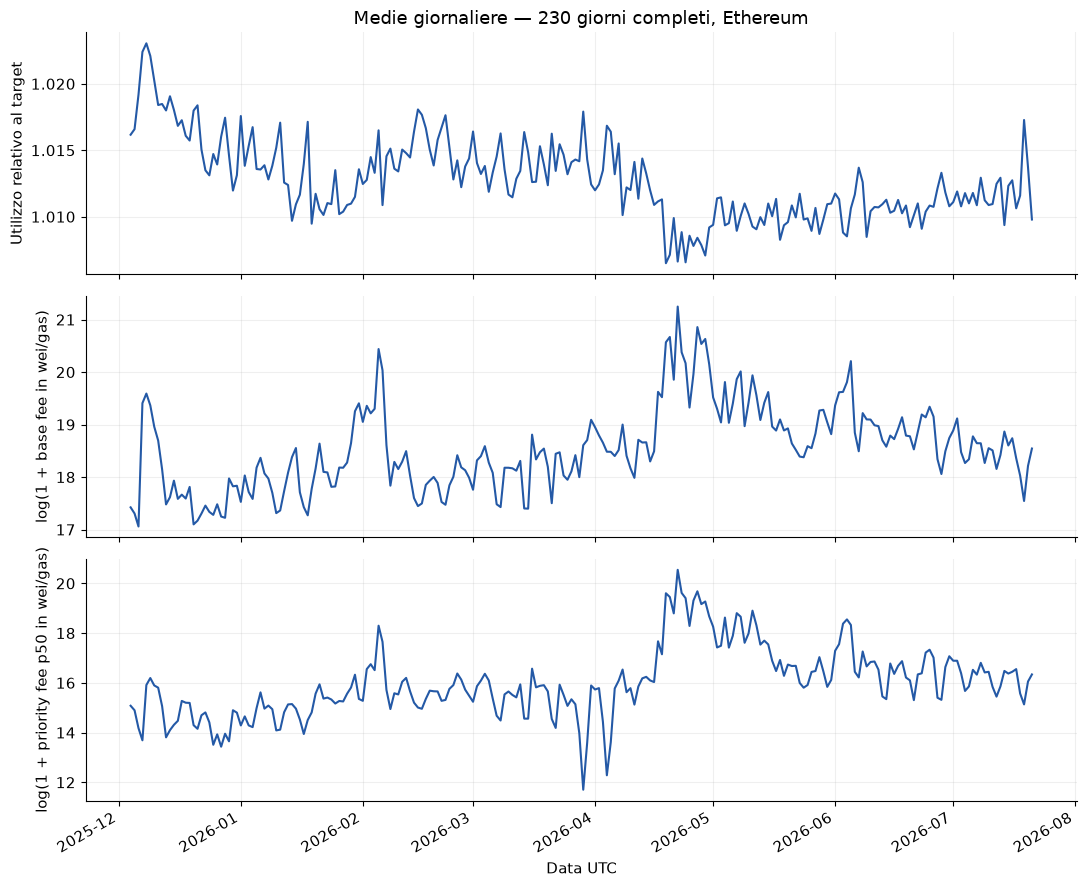

In [9]:
# shortcut: medie giornaliere, usare i blocchi per break intragiornalieri.
dated = df.set_index(pd.to_datetime(df.timestamp, unit="s", utc=True))
daily = (
    dated[
        [
            "X",
            *transformed,
            "tx_count",
            "gas_limit",
            "base_fee_gwei",
            "priority_fee_p50_gwei",
            "priority_fee_p90_gwei",
        ]
    ]
    .resample("D")
    .mean()
    .iloc[1:-1]
)
assert daily.notna().all().all() and len(daily) >= 60
daily.to_csv(output_directory / "daily_means.csv", index_label="data_UTC")
daily_test_rows = []
for column in ["X", *transformed]:
    for mode in ["livello", "differenza"]:
        values = daily[column] if mode == "livello" else daily[column].diff().dropna()
        adf = adfuller(values, maxlag=7, regression="c", autolag=None)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            result = kpss(values, regression="c", nlags=7)
        daily_test_rows.append(
            {
                "variabile": column,
                "trasformazione": mode,
                "n_giorni": len(values),
                "adf_p": adf[1],
                "kpss_p": result[1],
                "kpss_p_limitato": any(
                    issubclass(w.category, InterpolationWarning) for w in caught
                ),
                "lag_giorni": 7,
                "lettura": joint_interpretation(adf[1], result[1]),
            }
        )
daily_tests = pd.DataFrame(daily_test_rows)
daily_tests.to_csv(output_directory / "daily_stationarity_tests.csv", index=False)
display(daily_tests.round(5))
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, column, label in zip(
    axes,
    ["X", transformed[0], transformed[1]],
    [
        "Utilizzo relativo al target",
        "log(1 + base fee in wei/gas)",
        "log(1 + priority fee p50 in wei/gas)",
    ],
    strict=True,
):
    ax.plot(daily.index, daily[column], color="#2459A6")
    ax.set_ylabel(label)
axes[0].set_title(f"Medie giornaliere — {len(daily)} giorni completi, Ethereum")
axes[-1].set_xlabel("Data UTC")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## 10. Test di stabilità e data candidata

Localizziamo il maggiore cambiamento di media con almeno 14 giorni per segmento e un bootstrap a blocchi settimanali.
Il p-value corregge la ricerca fra date; Holm corregge le cinque serie. CUSUM è solo ausiliario e risente dell’autocorrelazione.

In [10]:
MIN_DAYS = 14
BOOTSTRAPS = 499
BLOCK_DAYS = 7
rng = np.random.default_rng(42)


def mean_shift(values):
    values = np.asarray(values, dtype=float)
    n = len(values)
    candidates = np.arange(MIN_DAYS, n - MIN_DAYS + 1)
    assert len(candidates) > 0 and np.isfinite(values).all()
    total = np.cumsum(values)
    left = total[candidates - 1] / candidates
    right = (total[-1] - total[candidates - 1]) / (n - candidates)
    scale = values.std(ddof=1)
    if scale == 0:
        return 0.0, int(candidates[0])
    scores = np.sqrt(candidates * (n - candidates) / n) * np.abs(left - right) / scale
    best = int(np.argmax(scores))
    return float(scores[best]), int(candidates[best])


assert mean_shift(np.ones(60))[0] == 0
assert mean_shift(np.r_[np.zeros(40), np.ones(40)])[1] == 40
break_rows = []
for column in ["X", *transformed]:
    values = daily[column].to_numpy()
    statistic, split = mean_shift(values)
    centered = values - values.mean()
    bootstrap_stats = []
    for _ in range(BOOTSTRAPS):
        starts_boot = rng.integers(0, len(values), size=int(np.ceil(len(values) / BLOCK_DAYS)))
        positions = ((starts_boot[:, None] + np.arange(BLOCK_DAYS)) % len(values)).ravel()
        bootstrap_stats.append(mean_shift(centered[positions[: len(values)]])[0])
    bootstrap_p = (1 + np.count_nonzero(np.asarray(bootstrap_stats) >= statistic)) / (
        BOOTSTRAPS + 1
    )
    cusum = breaks_cusumolsresid(centered, ddof=1)
    break_rows.append(
        {
            "variabile": column,
            "data_candidata_UTC": daily.index[split],
            "stat_max": statistic,
            "bootstrap_p": bootstrap_p,
            "media_prima": values[:split].mean(),
            "media_dopo": values[split:].mean(),
            "cusum_p_ausiliario": cusum[1],
        }
    )
breaks = pd.DataFrame(break_rows)
breaks["p_holm"] = multipletests(breaks.bootstrap_p, alpha=ALPHA, method="holm")[1]
breaks["evidenza_shift_media"] = breaks.p_holm < ALPHA
breaks.to_csv(output_directory / "mean_shift_tests.csv", index=False)
display(breaks.round(5))
print("Bootstrap a blocchi: approssimazione per dipendenza breve; non è Bai–Perron.")
print("Una data candidata è descrittiva se p_holm >= 0.05; non prova un cambio di regime causale.")

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/974870459.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(breaks.round(5))


,variabile,data_candidata_UTC,stat_max,bootstrap_p,media_prima,media_dopo,cusum_p_ausiliario,p_holm,evidenza_shift_media
0,X,2026-04-08 00:00:00+00:00,10.04480,0.002,1.01456,1.01058,0.0,0.010,True
1,log_base_fee_per_gas,2026-04-17 00:00:00+00:00,8.93268,0.002,18.14512,19.10477,0.0,0.010,True
2,log_effective_priority_fee_per_gas_p50,2026-04-13 00:00:00+00:00,10.05148,0.002,15.18397,17.05061,0.0,0.010,True
3,log_effective_priority_fee_per_gas_p90,2026-04-15 00:00:00+00:00,6.06395,0.038,20.51726,20.85464,0.0,0.038,True
4,priority_fee_dispersion,2026-04-12 00:00:00+00:00,11.02363,0.002,5.34103,3.80261,0.0,0.010,True


Bootstrap a blocchi: approssimazione per dipendenza breve; non è Bai–Perron.
Una data candidata è descrittiva se p_holm >= 0.05; non prova un cambio di regime causale.


## 11. Attività e condizioni del protocollo attorno alle date

Confrontiamo attività e gas limit nei 14 giorni precedenti e successivi a ogni data candidata.
Queste evidenze interne possono motivare approfondimenti; non identificano aggiornamenti di protocollo o cause di mercato.

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/2370560760.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(activity_context.round(4))


,variabile_break,data_candidata_UTC,periodo,giorni,X,tx_count,gas_limit,base_fee_gwei,priority_fee_p50_gwei
0,X,2026-04-08 00:00:00+00:00,prima,14,1.0143,324.4293,5.999057e+07,0.1290,0.4580
1,X,2026-04-08 00:00:00+00:00,dopo,14,1.0112,328.1138,5.999052e+07,0.4203,0.2237
2,log_base_fee_per_gas,2026-04-17 00:00:00+00:00,prima,14,1.0133,346.8387,5.999061e+07,0.1301,0.1720
3,log_base_fee_per_gas,2026-04-17 00:00:00+00:00,dopo,14,1.0084,330.1481,5.999050e+07,1.1031,0.5220
4,log_effective_priority_fee_per_gas_p50,2026-04-13 00:00:00+00:00,prima,14,1.0133,346.4599,5.999064e+07,0.1395,0.2422
5,log_effective_priority_fee_per_gas_p50,2026-04-13 00:00:00+00:00,dopo,14,1.0096,295.4761,5.999044e+07,0.7953,0.4188
6,log_effective_priority_fee_per_gas_p90,2026-04-15 00:00:00+00:00,prima,14,1.0134,351.0170,5.999064e+07,0.1345,0.2064
7,log_effective_priority_fee_per_gas_p90,2026-04-15 00:00:00+00:00,dopo,14,1.0088,309.6175,5.999054e+07,0.9719,0.4806
8,priority_fee_dispersion,2026-04-12 00:00:00+00:00,prima,14,1.0138,328.4510,5.999059e+07,0.1380,0.2582
9,priority_fee_dispersion,2026-04-12 00:00:00+00:00,dopo,14,1.0099,307.7311,5.999041e+07,0.7379,0.3889


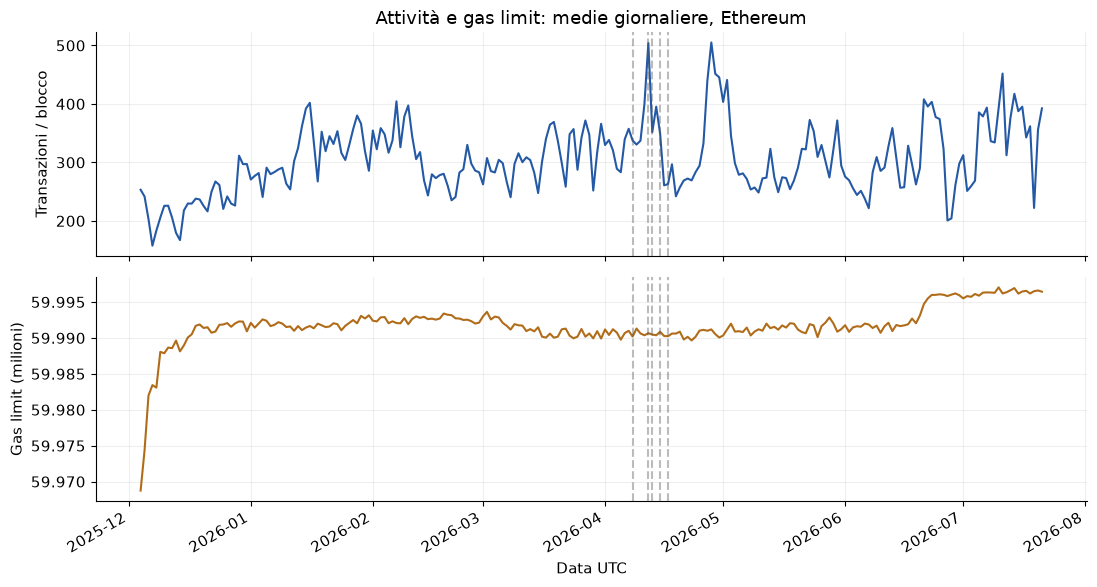

Linee: date con evidenza bootstrap/Holm; associazioni temporali, non attribuzioni causali.


In [11]:
context_rows = []
for row in breaks.itertuples():
    date = row.data_candidata_UTC
    for label, part in [
        ("prima", daily.loc[(daily.index >= date - pd.Timedelta(days=14)) & (daily.index < date)]),
        ("dopo", daily.loc[(daily.index >= date) & (daily.index < date + pd.Timedelta(days=14))]),
    ]:
        context_rows.append(
            {
                "variabile_break": row.variabile,
                "data_candidata_UTC": date,
                "periodo": label,
                "giorni": len(part),
                **part[["X", "tx_count", "gas_limit", "base_fee_gwei", "priority_fee_p50_gwei"]]
                .mean()
                .to_dict(),
            }
        )
activity_context = pd.DataFrame(context_rows)
activity_context.to_csv(output_directory / "break_activity_context.csv", index=False)
display(activity_context.round(4))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily.index, daily.tx_count, color="#2459A6")
axes[0].set(
    ylabel="Transazioni / blocco", title="Attività e gas limit: medie giornaliere, Ethereum"
)
axes[1].plot(daily.index, daily.gas_limit / 1e6, color="#B06C19")
axes[1].set(ylabel="Gas limit (milioni)", xlabel="Data UTC")
for ax in axes:
    for date in breaks.loc[breaks.evidenza_shift_media, "data_candidata_UTC"].unique():
        ax.axvline(date, color="#555555", linestyle="--", alpha=0.4)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)
print("Linee: date con evidenza bootstrap/Holm; associazioni temporali, non attribuzioni causali.")

## 12. Conclusioni verificabili e anomalie da discutere

Raccogliamo esiti discordanti, sensibilità alla specificazione e cambiamenti osservati senza attribuzioni causali.
La scelta finale delle trasformazioni richiede anche dipendenza seriale e validazione fuori campione negli step successivi.

In [12]:
conflicts = stationarity[stationarity.lettura == "possibili break o specificazione inadeguata"]
changed_specs = sensitivity.groupby("variabile").lettura.nunique().rename("letture_distinte")
display(changed_specs.to_frame())
display(breaks[breaks.evidenza_shift_media].round(5))
print("Confronti ADF/KPSS:", len(stationarity), "| esiti discordanti:", len(conflicts))
print("Serie con lettura sensibile a trend/lag:", int((changed_specs > 1).sum()))
print("Il log limita la scala delle fee; X conserva il vincolo fisico [0, 2].")
print("Non differenziare tutte le serie automaticamente; nessuna causa esterna è verificata.")
print("Risultati:", output_directory)

,letture_distinte
variabile,
X,1
log_base_fee_per_gas,1
log_effective_priority_fee_per_gas_p50,1
log_effective_priority_fee_per_gas_p90,1
priority_fee_dispersion,1


/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_18055/311132921.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(breaks[breaks.evidenza_shift_media].round(5))


,variabile,data_candidata_UTC,stat_max,bootstrap_p,media_prima,media_dopo,cusum_p_ausiliario,p_holm,evidenza_shift_media
0,X,2026-04-08 00:00:00+00:00,10.04480,0.002,1.01456,1.01058,0.0,0.010,True
1,log_base_fee_per_gas,2026-04-17 00:00:00+00:00,8.93268,0.002,18.14512,19.10477,0.0,0.010,True
2,log_effective_priority_fee_per_gas_p50,2026-04-13 00:00:00+00:00,10.05148,0.002,15.18397,17.05061,0.0,0.010,True
3,log_effective_priority_fee_per_gas_p90,2026-04-15 00:00:00+00:00,6.06395,0.038,20.51726,20.85464,0.0,0.038,True
4,priority_fee_dispersion,2026-04-12 00:00:00+00:00,11.02363,0.002,5.34103,3.80261,0.0,0.010,True


Confronti ADF/KPSS: 36 | esiti discordanti: 19
Serie con lettura sensibile a trend/lag: 0
Il log limita la scala delle fee; X conserva il vincolo fisico [0, 2].
Non differenziare tutte le serie automaticamente; nessuna causa esterna è verificata.
Risultati: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step4
